In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
fechas = pd.date_range("2026-10-01", periods=30, freq="D")

ventas = [
    320, 340, 520, 560, 300, 310, None,
    330, 345, 540, 580, 315, None, 325,
    350, 335, 545, 590, 310, 320, None,
    340, 355, 560, 600, None, 345, None,
    360, 350,
]

serie = pd.Series(ventas, index=fechas, name="ventas_usd")
print("--- Serie original (primeros 10) ---")
print(serie.head(10))

--- Serie original (primeros 10) ---
2026-10-01    320.0
2026-10-02    340.0
2026-10-03    520.0
2026-10-04    560.0
2026-10-05    300.0
2026-10-06    310.0
2026-10-07      NaN
2026-10-08    330.0
2026-10-09    345.0
2026-10-10    540.0
Freq: D, Name: ventas_usd, dtype: float64


### Detectar elementos faltantes

In [14]:
print("\nDatos faltantes:", serie.isna().sum())


Datos faltantes: 5


### Como van a rellenar eso?

In [15]:
media = serie.mean()
mediana = serie.median()

print("\nMedia: ", round(media, 2))
print("Mediana: ", round(mediana, 2))


Media:  405.8
Mediana:  345.0


In [ ]:
# Opcion 1 : Usar Dropna

In [16]:
serie_sin_faltantes = serie.dropna()
print("\nDatos faltantes:", serie_sin_faltantes.isna().sum())


Datos faltantes: 0


In [ ]:
#Opcion 2: Rellenar

In [17]:
serie_cero = serie.fillna(0)
serie_media = serie.fillna(media)
serie_mediana = serie.fillna(mediana)

In [21]:
comparacion = pd.Series( {
    "Serie original": serie.mean(),
    "Serie sin faltantes": serie_sin_faltantes.mean(),
    "Serie con ceros": serie_cero.mean(),
    "Serie con media": serie_media.mean(),
    "Serie con mediana": serie_mediana.mean(),
}).round(2)

print("\nComparacion de medias")

print(comparacion.head(10))


Comparacion de medias
Serie original         405.80
Serie sin faltantes    405.80
Serie con ceros        338.17
Serie con media        405.80
Serie con mediana      395.67
dtype: float64


###Sacar informacion util

In [22]:
serie_limpia = serie.fillna(mediana)

In [23]:
print(serie_limpia.describe())

count     30.000000
mean     395.666667
std      103.746486
min      300.000000
25%      331.250000
50%      345.000000
75%      480.000000
max      600.000000
Name: ventas_usd, dtype: float64


In [24]:
print("Ventas totales del mes: $", serie_limpia.sum())

Ventas totales del mes: $ 11870.0


In [25]:
# Mejor y Peor Dia

print("Mejor dia: $", serie_limpia.max())
print("Peor dia: $", serie_limpia.min())

Mejor dia: $ 600.0
Peor dia: $ 300.0


In [27]:
print("Mejor dia:", serie_limpia.idxmax().date(), "con $", serie_limpia.max())
print("Peor dia:", serie_limpia.idxmin().date(), "con $", serie_limpia.min())

Mejor dia: 2026-10-25 con $ 600.0
Peor dia: 2026-10-05 con $ 300.0


In [ ]:
# cuando vendemos mas en la semana?

In [33]:
dias = ["Lunes", "Martes", "Miercoles", "Jueves", "Viernes", "Sabado", "Domingo"]

por_dia = serie_limpia.groupby(serie_limpia.index.dayofweek).mean()
por_dia.index = dias
print(por_dia)

Lunes        317.50
Martes       330.00
Miercoles    340.00
Jueves       340.00
Viernes      345.00
Sabado       541.25
Domingo      582.50
Name: ventas_usd, dtype: float64


### Graficas

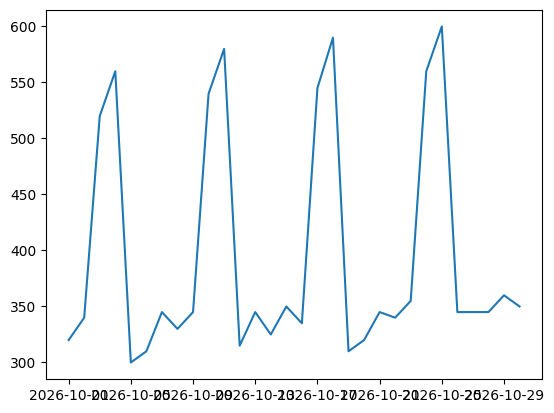

In [34]:
#Grafica con Matplot

plt.plot(serie_limpia)
plt.show()

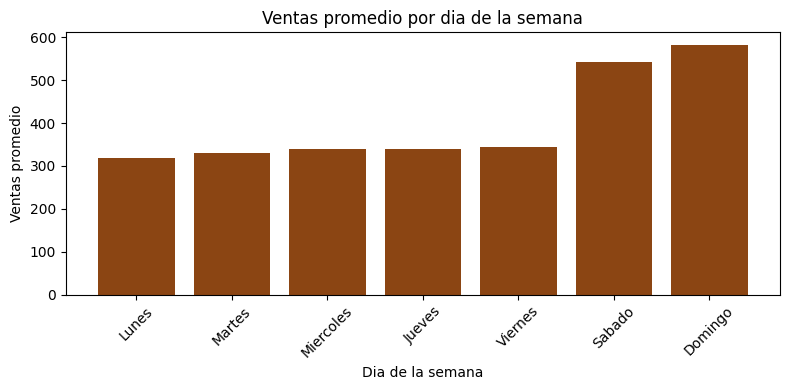

In [41]:
plt.figure(figsize=(8,4))
plt.bar(por_dia.index, por_dia.values, color="saddlebrown")
plt.title("Ventas promedio por dia de la semana")
plt.xlabel("Dia de la semana")
plt.ylabel("Ventas promedio")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("ventasxdia.png") # Guardamos/descargamos
plt.show()

### Se puede descargar con "savefig"

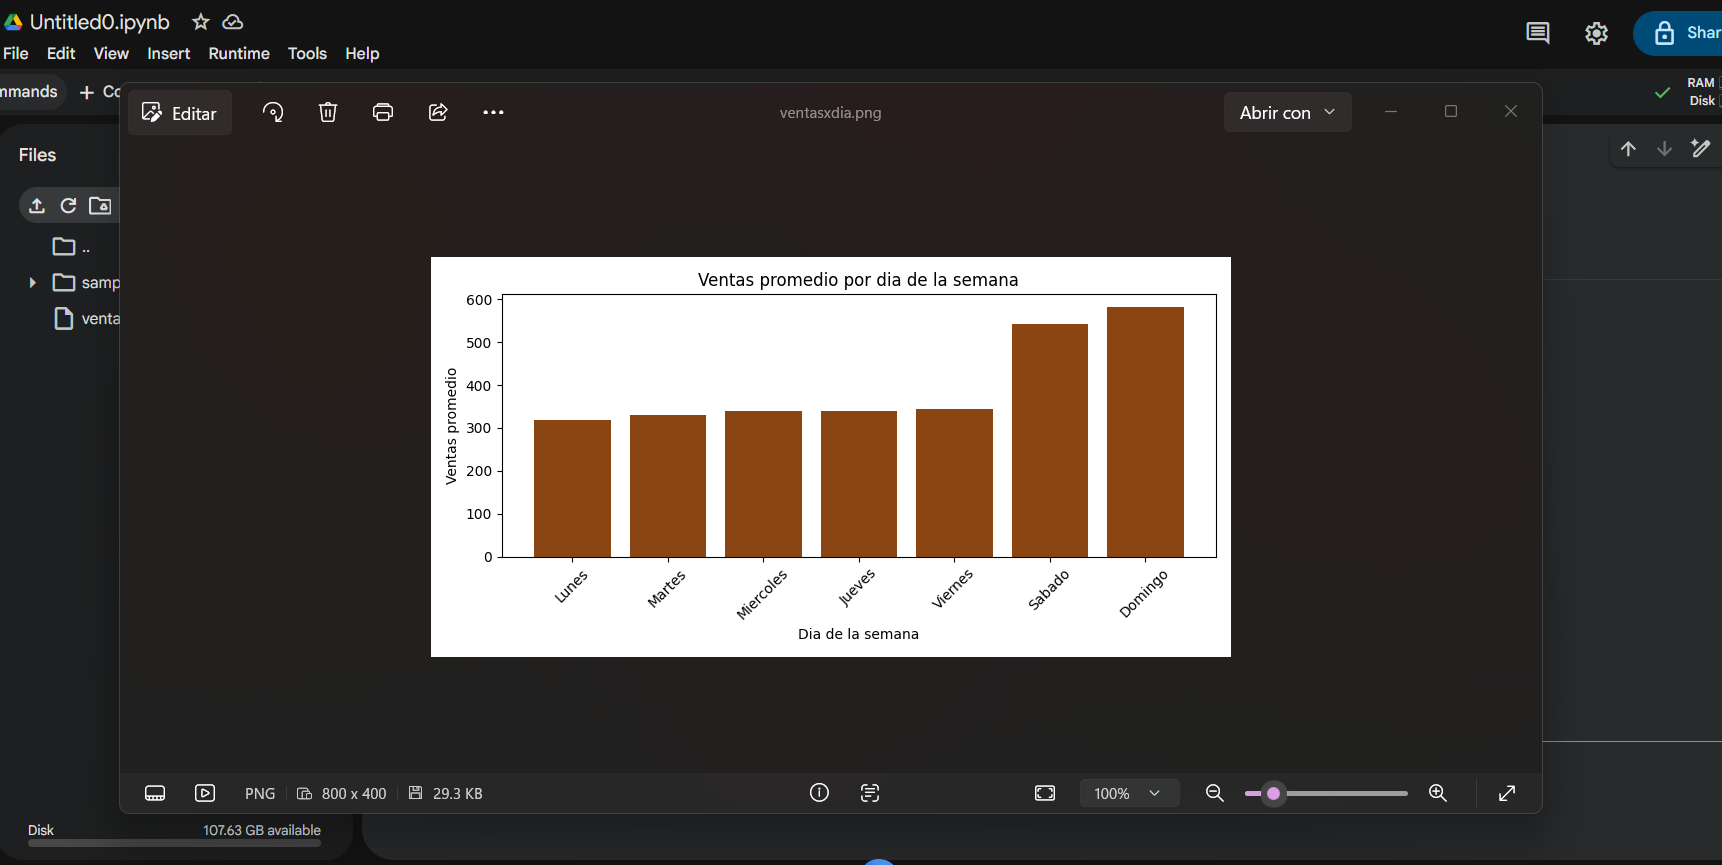

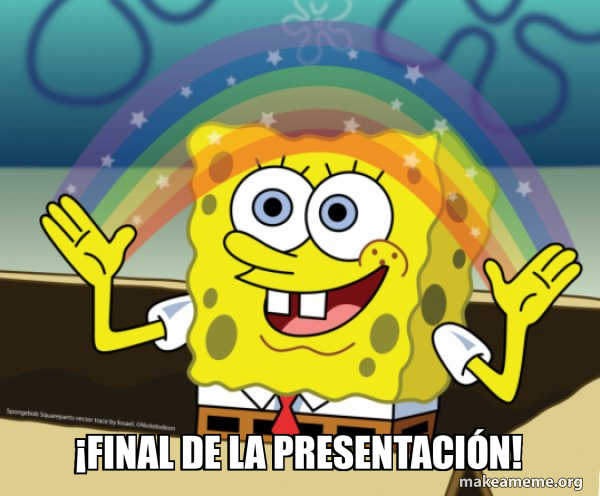